# 01. Pemahaman Bisnis, Pengumpulan Data & Eksplorasi Data (EDA)

**Tujuan:** Merumuskan masalah bisnis, pertanyaan penelitian, sumber dan kamus data, serta melakukan audit kesehatan data (*Data Quality Audit*) dan Eksplorasi Visual & Statistik (*EDA*) sebelum tahap pembersihan dan pemodelan.

## 1. Pemahaman Bisnis (*Business Understanding*)

### 1.1 Latar Belakang Masalah & Alasan Pemilihan Dataset
Transisi energi menuju sumber terbarukan di Amerika Serikat menunjukkan perbedaan karakteristik yang tajam antar-sektor pengguna (*Electric Power, Industrial, Residential, Commercial, Transportation*) serta fluktuasi musiman bulanan yang dipengaruhi kondisi alam dan siklus operasional. Ketimpangan skala dan pola musiman antar-sektor ini membuat perencanaan kapasitas jaringan listrik (*grid*), penjadwalan pemeliharaan infrastruktur, dan strategi kontrak pengadaan energi (*Power Purchase Agreement*) memerlukan model prediksi kuantitatif alih-alih perkiraan rata-rata kasar.

**Alasan Pemilihan Dataset:**
- **Relevansi & Kredibilitas:** Bersumber langsung dari publikasi resmi pemerintah AS (*U.S. Energy Information Administration / EIA Monthly Energy Review*).
- **Rentang Temporal Panjang:** Mencakup 51 tahun catatan bulanan historis (`Januari 1973 – Januari 2024`, `3.065` observasi awal), memadai untuk memisahkan tren jangka panjang dari siklus musiman serta melakukan validasi *Out-of-Time* (`2019–2023`).
- **Keterbukaan & Kelengkapan:** Berlisensi publik (*U.S. Government Works*) dengan nol *missing value* eksplisit (`NaN`) dan struktur granular per sektor serta sumber energi dalam satuan standar `Trillion BTU`.

### 1.2 Pertanyaan Penelitian (*Research Questions*)
1. Bagaimana pola perbedaan konsumsi energi terbarukan di Amerika Serikat antar **sektor pengguna**, **siklus bulanan (musiman)**, dan **tren tahunan**?
2. Faktor prediktor apa (`t`, `Sector`, `Sector × t`, `Month`, maupun fitur *lag*) yang memberikan kontribusi paling besar dalam menjelaskan variasi total konsumsi energi terbarukan?
3. Seberapa akurat model **Regresi** (serta perbandingannya dengan *baseline* dan model penantang deret waktu) dalam memprediksi konsumsi energi terbarukan pada data uji *Out-of-Time* (`2019–2023`)?
4. Bagaimana hasil estimasi model dan pola beban puncak musiman dapat diterjemahkan menjadi rekomendasi penjadwalan pemeliharaan *grid* dan alokasi insentif kebijakan energi?

### 1.3 Metode & Metrik Keberhasilan (*SMART Objectives*)
- **Metode Utama:** **Regresi** (*Multiple Linear Regression / OLS* dalam kerangka *CRISP-DM* dan *Ablation Study* bertahap), dilengkapi diagnostik 4 asumsi klasik OLS + koreksi *Newey-West HAC*, serta pembanding berbasis hasil diagnostik residual.
- **Target Evaluasi Model (*Out-of-Time Test 2019–2023*):**
  - $Adjusted\ R^2 \ge 0.80$
  - $\text{RMSE} \le 40\text{ Trillion BTU}$
  - $\text{MAPE} < 10\%$ (beserta metrik pelengkap $\text{MAE}$)
  - Mampu melampaui tolok ukur dasar (*Baseline Trend OLS* dan *Seasonal Naive*).
- **Kriteria Statistik EDA & Diagnostik:** Uji beda One-Way ANOVA & Kruskal-Wallis ($\alpha = 0.05$); $\text{VIF} < 5$, Durbin-Watson, Breusch-Pagan, dan Jarque-Bera.

---

## 2. Pengumpulan Data & Kamus Data (*Data Gathering & Data Dictionary*)

### 2.1 Sumber Data dan Lisensi
Dataset yang digunakan dalam penelitian ini adalah **U.S. Renewable Energy Consumption** yang disusun oleh Alistair King di platform Kaggle:
- **Tautan Dataset:** https://www.kaggle.com/datasets/alistairking/renewable-energy-consumption-in-the-u-s
- **Sumber Data Primer:** *U.S. Energy Information Administration (EIA)*, melalui publikasi resmi bulanan [*Monthly Energy Review*](https://www.eia.gov/totalenergy/data/monthly/).
- **Lisensi Data:** **U.S. Government Works** (Karya Pemerintah Federal AS), berada di ranah publik (*Public Domain*) sehingga bebas digunakan untuk analisis akademik, modifikasi, dan publikasi penelitian.
- **Satuan Pengukuran:** Seluruh variabel konsumsi energi dinyatakan dalam satuan standar energi panas: **trillion British Thermal Units (trillion BTU)**.
- **Cakupan Awal:** Berisi `3.065` baris observasi bulanan (`613` bulan unik $\times$ `5` sektor pengguna energi), merentang dari **Januari 1973 sampai Januari 2024** dengan `17` kolom mentah.

### 2.2 Kamus Data (*Data Dictionary*)
Berikut adalah kamus data resmi yang merinci ke-17 variabel mentah pada dataset serta variabel hasil transformasi di tahap *Cleaning* dan *Feature Engineering*:

| No | Nama Kolom | Tipe Data Asli | Satuan | Kategori / Peran | Definisi & Keterangan |
|:---:|---|:---:|:---:|:---:|---|
| 1 | `Year` | Integer (`int64`) | Tahun | Temporal | Tahun pencatatan observasi (`1973 – 2024`). |
| 2 | `Month` | Integer (`int64`) | Bulan (`1–12`) | Temporal | Bulan pencatatan observasi (`Januari = 1`, `Desember = 12`). |
| 3 | `Sector` | String (`object`) | Kategori | Kategorikal | Sektor pengguna energi: *Electric Power, Industrial, Residential, Commercial, Transportation*. |
| 4 | `Hydroelectric Power` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi pembangkit listrik tenaga air (*Industrial & Commercial*). |
| 5 | `Geothermal Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi panas bumi untuk listrik atau pemanas langsung. |
| 6 | `Solar Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi surya fotovoltaik (PV) dan termal surya. |
| 7 | `Wind Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi angin untuk pembangkitan listrik skala utilitas. |
| 8 | `Wood Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi biomassa kayu (pelet, serpihan kayu, limbah kayu). |
| 9 | `Waste Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi dari limbah padat perkotaan (*municipal solid waste*). |
| 10 | `Fuel Ethanol, Excluding Denaturant` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi bioetanol murni sebagai bahan bakar terbarukan. |
| 11 | `Biomass Losses and Co-products` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Kehilangan energi dan produk samping selama proses konversi biomassa. |
| 12 | `Biomass Energy` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Total konsumsi seluruh sub-varian energi berbasis biomassa. |
| 13 | `Total Renewable Energy` | Float (`float64`) | trillion BTU | **Variabel Target ($y$)** | Total keseluruhan konsumsi energi terbarukan pada sektor dan bulan terkait. |
| 14 | `Renewable Diesel Fuel` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Bahan bakar diesel terbarukan sintetis (*hydrotreated vegetable oil*). |
| 15 | `Other Biofuels` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Bahan bakar nabati lainnya di luar etanol dan biodiesel standar. |
| 16 | `Conventional Hydroelectric Power` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi energi hidro konvensional (*Electric Power*). |
| 17 | `Biodiesel` | Float (`float64`) | trillion BTU | Fitur Numerik *(mentah)* | Konsumsi bahan bakar nabati ester metil asam lemak (biodiesel). |
| *18* | `hydro` *(dibersihkan)* | Float (`float64`) | trillion BTU | Fitur Turunan | Kolom terpadu hasil penggabungan `Hydroelectric Power` dan `Conventional Hydroelectric Power` di notebook `02`. |
| *19* | `date` *(bantu EDA)* | Datetime (`datetime64`) | `YYYY-MM-01` | Temporal *(sementara)* | Kolom tanggal bantu sementara untuk keperluan grafik deret waktu di notebook EDA. |
| *20* | `t` *(rekayasa fitur)* | Integer (`int64`) | Indeks Bulan | Temporal / Tren | Indeks waktu kronologis kontinu dari bulan ke-`0` (Jan 1973) hingga `611` (Des 2023) di notebook `03`. |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

In [2]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
DATA_PATH = Path('../data/raw/dataset.csv')

In [3]:
raw_df = pd.read_csv(DATA_PATH)
raw_df.head()

,Year,Month,Sector,Hydroelectric Power,Geothermal Energy,Solar Energy,Wind Energy,Wood Energy,Waste Energy,"Fuel Ethanol, Excluding Denaturant",Biomass Losses and Co-products,Biomass Energy,Total Renewable Energy,Renewable Diesel Fuel,Other Biofuels,Conventional Hydroelectric Power,Biodiesel
0,1973,1,Commerical,0.00,0.00,0.0,0.0,0.570,0.000,0.0,0.0,0.570,0.570,0.0,0.0,0.000,0.0
1,1973,1,Electric Power,0.00,0.49,0.0,0.0,0.054,0.157,0.0,0.0,0.211,89.223,0.0,0.0,88.522,0.0
2,1973,1,Industrial,1.04,0.00,0.0,0.0,98.933,0.000,0.0,0.0,98.933,99.973,0.0,0.0,0.000,0.0
3,1973,1,Residential,0.00,0.00,0.0,0.0,30.074,0.000,0.0,0.0,0.000,30.074,0.0,0.0,0.000,0.0
4,1973,1,Transportation,0.00,0.00,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.0


In [4]:
raw_df.shape

(3065, 17)

---

## 3. Audit Kualitas & Forensik Data

Pada tahap ini dilakukan pemeriksaan kesehatan data secara menyeluruh terhadap `raw_df` (`3.065` baris $\times$ `17` kolom): keunikan kunci komposit, inflasi nilai nol (*zero-inflation*), integritas kategori, redundansi fitur, dan anomali nilai negatif sebelum menyusun rencana pembersihan (*Action Plan*).

### 3.1 Validasi Granularitas Data & Keunikan Baris
**Tujuan:** Memastikan setiap baris merepresentasikan kombinasi unik `(Year, Month, Sector)` dan mengecek apakah terdapat data duplikat di dalam dataset.

In [5]:
# check for full-row duplicates
duplicate_rows = raw_df.duplicated().sum()

composite_key = ['Year', 'Month', 'Sector']
key_duplicates = raw_df.duplicated(subset=composite_key).sum()

print(f"Total rows: {len(raw_df):,}")
print(f"Full row duplicates: {duplicate_rows}")
print(f"Composite key ({composite_key}) duplicates: {key_duplicates}")

Total rows: 3,065
Full row duplicates: 0
Composite key (['Year', 'Month', 'Sector']) duplicates: 0


### 3.2 Audit Kesehatan Data Komprehensif
**Tujuan:** Memeriksa tipe data tiap kolom, nilai kosong eksplisit (`NaN`), ketiadaan data implisit yang dikodekan sebagai nol (*zero-inflation*), serta jumlah nilai unik.

In [6]:
def audit_data_health(df: pd.DataFrame) -> pd.DataFrame:
    """Builds a high-level data health and schema audit table."""
    audit = pd.DataFrame({
        'dtype': df.dtypes,
        'non_null_count': df.notna().sum(),
        'null_count': df.isna().sum(),
        'null_pct (%)': (df.isna().mean() * 100).round(2),
        'zero_count': (df == 0).sum(),
        'zero_pct (%)': ((df == 0).mean() * 100).round(2),
        'unique_values': df.nunique(),
        'sample_value': df.iloc[0]
    })
    return audit.sort_values(by='zero_pct (%)', ascending=False)

In [7]:
audit_summary = audit_data_health(raw_df)
audit_summary

,dtype,non_null_count,null_count,null_pct (%),zero_count,zero_pct (%),unique_values,sample_value
Other Biofuels,float64,3065,0,0.0,2944,96.05,115,0.0
Renewable Diesel Fuel,float64,3065,0,0.0,2908,94.88,158,0.0
Biodiesel,float64,3065,0,0.0,2788,90.96,270,0.0
Biomass Losses and Co-products,float64,3065,0,0.0,2548,83.13,405,0.0
Conventional Hydroelectric Power,float64,3065,0,0.0,2452,80.00,613,0.0
Wind Energy,float64,3065,0,0.0,2274,74.19,473,0.0
Hydroelectric Power,float64,3065,0,0.0,2040,66.56,509,0.0
"Fuel Ethanol, Excluding Denaturant",float64,3065,0,0.0,1514,49.40,939,0.0
Waste Energy,float64,3065,0,0.0,1514,49.40,1381,0.0
Solar Energy,float64,3065,0,0.0,1330,43.39,1054,0.0


In [8]:
raw_df.Sector.value_counts()

Sector
Commerical        613
Electric Power    613
Industrial        613
Residential       613
Transportation    613
Name: count, dtype: int64

### 3.3 Pemeriksaan Integritas Kategori: `Sector`
**Tujuan:** Menginspeksi distribusi nilai unik pada fitur kategorikal `Sector` untuk mendeteksi kesalahan ketik (*typo*), inkonsistensi huruf, atau kategori minor.

In [9]:
sector_counts = raw_df['Sector'].value_counts(dropna=False).to_frame(name='record_count')
sector_counts['pct_share (%)'] = (sector_counts['record_count'] / len(raw_df) * 100).round(2)
sector_counts

,record_count,pct_share (%)
Sector,,
Commerical,613,20.0
Electric Power,613,20.0
Industrial,613,20.0
Residential,613,20.0
Transportation,613,20.0


### 3.4 Distribusi Numerik, Kemiringan (*Skewness*), & Batas Nilai
**Tujuan:** Mengevaluasi batas minimum/maksimum, persentase angka nol, serta kemiringan distribusi (*skewness*) seluruh fitur energi numerik.

In [10]:
num_cols = raw_df.select_dtypes(include=[np.number]).columns.drop(['Year','Month'])
num_cols

Index(['Hydroelectric Power', 'Geothermal Energy', 'Solar Energy',
       'Wind Energy', 'Wood Energy', 'Waste Energy',
       'Fuel Ethanol, Excluding Denaturant', 'Biomass Losses and Co-products',
       'Biomass Energy', 'Total Renewable Energy', 'Renewable Diesel Fuel',
       'Other Biofuels', 'Conventional Hydroelectric Power', 'Biodiesel'],
      dtype='object')

In [11]:
num_stats = pd.DataFrame({
    'min': raw_df[num_cols].min(),
    'max': raw_df[num_cols].max(),
    'mean': raw_df[num_cols].mean(),
    'median': raw_df[num_cols].median(),
    'skewness':raw_df[num_cols].skew().round(2),
    'std': raw_df[num_cols].std()
})

num_stats['skew_category'] = num_stats['skewness'].apply(
    lambda x: 'Highly Skewed (Right)' if x > 1 else ('Highly skewed (Left)' if x < - 1 else 'Moderate / Symmetric')
)
num_stats

,min,max,mean,median,skewness,std,skew_category
Hydroelectric Power,-0.002,2.047,0.169759,0.000,2.35,0.373819,Highly Skewed (Right)
Geothermal Energy,0.000,5.951,1.146369,0.357,1.23,1.550857,Highly Skewed (Right)
Solar Energy,0.000,64.040,2.015008,0.004,5.37,5.774511,Highly Skewed (Right)
Wind Energy,0.000,157.409,4.282404,0.000,5.04,18.124793,Highly Skewed (Right)
Wood Energy,0.000,183.628,36.644408,12.062,1.14,46.900639,Highly Skewed (Right)
Waste Energy,0.000,32.875,5.820124,0.108,1.12,8.247359,Highly Skewed (Right)
"Fuel Ethanol, Excluding Denaturant",0.000,104.420,6.976648,0.007,3.44,21.911920,Highly Skewed (Right)
Biomass Losses and Co-products,0.000,75.373,4.834706,0.000,3.47,15.601717,Highly Skewed (Right)
Biomass Energy,0.000,233.200,46.285969,9.716,1.25,64.241520,Highly Skewed (Right)
Total Renewable Energy,0.000,308.175,70.872209,50.984,0.76,71.197761,Moderate / Symmetric


### 3.5 Forensik Variabel Target: Inflasi Nilai Nol per Sektor
**Tujuan:** Mengidentifikasi sektor mana yang menyebabkan munculnya 613 baris (20%) bernilai nol pada target `Total Renewable Energy`, serta mengecek konsistensi penjumlahan sub-komponen biomassa.

In [12]:
zero_target_by_sector = raw_df.groupby('Sector')['Total Renewable Energy'].agg(
    total_records='count',
    zero_records= lambda x: (x==0).sum(),
    zero_pct= lambda x: round((x==0).sum() * 100, 2),
    mean_value='mean',
    max_value='max'
)
zero_target_by_sector

,total_records,zero_records,zero_pct,mean_value,max_value
Sector,,,,,
Commerical,613,0,0,8.987750,24.945
Electric Power,613,0,0,132.569471,308.175
Industrial,613,0,0,159.825390,234.425
Residential,613,0,0,52.978434,85.781
Transportation,613,613,61300,0.000000,0.000


In [13]:
# Identify the whole columns where the TRE is 0
zero_tre = raw_df[raw_df['Total Renewable Energy'] == 0]
# zero_tre.Sector.value_counts()
zero_tre.head()

,Year,Month,Sector,Hydroelectric Power,Geothermal Energy,Solar Energy,Wind Energy,Wood Energy,Waste Energy,"Fuel Ethanol, Excluding Denaturant",Biomass Losses and Co-products,Biomass Energy,Total Renewable Energy,Renewable Diesel Fuel,Other Biofuels,Conventional Hydroelectric Power,Biodiesel
4,1973,1,Transportation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,1973,2,Transportation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,1973,3,Transportation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19,1973,4,Transportation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24,1973,5,Transportation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
check_columns = ['Hydroelectric Power', 'Geothermal Energy',
       'Solar Energy', 'Wind Energy', 'Wood Energy', 'Waste Energy',
       'Fuel Ethanol, Excluding Denaturant', 'Biomass Losses and Co-products',
       'Biomass Energy', 'Renewable Diesel Fuel',
       'Other Biofuels', 'Conventional Hydroelectric Power', 'Biodiesel']
       
(zero_tre[check_columns] == 0).mean() * 100

Hydroelectric Power                   100.000000
Geothermal Energy                     100.000000
Solar Energy                          100.000000
Wind Energy                           100.000000
Wood Energy                           100.000000
Waste Energy                          100.000000
Fuel Ethanol, Excluding Denaturant     15.660685
Biomass Losses and Co-products        100.000000
Biomass Energy                         15.660685
Renewable Diesel Fuel                  74.388254
Other Biofuels                         80.261011
Conventional Hydroelectric Power      100.000000
Biodiesel                              54.812398
dtype: float64

In [15]:
biomass_columns = [
    'Wood Energy',
    'Waste Energy',
    'Fuel Ethanol, Excluding Denaturant',
    'Biodiesel',
    'Renewable Diesel Fuel',
    'Other Biofuels',
    'Biomass Losses and Co-products',
]

check_total = pd.DataFrame({
    'Total Component': raw_df[biomass_columns].sum(axis=1),
    'Biomass Energy': raw_df['Biomass Energy']
})

check_total = check_total[check_total['Total Component'] == check_total['Biomass Energy']]
check_total.shape

# Sebanyak 1492 data ternyata memiliki nilai yang sama dengan biomass energy based on child component 

(1492, 2)

### 3.6 Audit Fitur: Redundansi Dua Kolom Hidro
**Tujuan:** Membuktikan apakah `Hydroelectric Power` dan `Conventional Hydroelectric Power` terpisah secara saling meniadakan (*mutually exclusive*) antar-sektor.

In [16]:
hydro_comparison = raw_df.groupby("Sector")[
    ["Hydroelectric Power", "Conventional Hydroelectric Power"]
].agg(lambda x: (x > 0).sum()
).rename(columns={
    'Hydroelectric Power' : 'records_with_hydro (>0)',
    'Conventional Hydroelectric Power': 'records_with_conv_hydro (>0)'
})
hydro_comparison

,records_with_hydro (>0),records_with_conv_hydro (>0)
Sector,,
Commerical,411,0
Electric Power,0,613
Industrial,613,0
Residential,0,0
Transportation,0,0


### 3.7 Pelanggaran Batas Fisik: Investigasi Nilai Negatif
**Tujuan:** Mengisolasi baris yang memiliki nilai energi negatif untuk memastikan apakah berasal dari kesalahan pencatatan atau fenomena fisik operasional pembangkit hidro (*station service power*).

In [17]:
negative_rows = raw_df[raw_df['Hydroelectric Power'] < 0]
negative_rows[['Year','Month','Hydroelectric Power','Total Renewable Energy']]

,Year,Month,Hydroelectric Power,Total Renewable Energy
2075,2007,8,-0.002,9.999


---
### 3.8 Ringkasan Audit Kualitas Data & Rencana Tindakan Pembersihan (Action Plan)

Berdasarkan audit forensik pada tahap *Data Understanding*, berikut adalah rangkuman anomali yang ditemukan beserta keputusan teknis yang akan dieksekusi pada tahap **Data Cleaning (`02_data_cleaning.ipynb`)**:

| No | Anomali / Temuan Data | Bukti Kuantitatif | Akar Masalah (Domain EIA) | Keputusan & Rencana Aksi |
|:---:|---|---|---|---|
| **1** | **Typo pada Kategori Sektor** | 613 baris tertulis `"Commerical"` | Kesalahan pengetikan (*human typo*) pada data mentah | Lakukan standardisasi teks: `"Commerical"` $\rightarrow$ `"Commercial"`. |
| **2** | **Target Variabel Cacat di Sektor Transportasi** | 100% baris (613/613) pada `Total Renewable Energy` bernilai `0.0` | EIA tidak menjumlahkan biofuel transportasi ke dalam kolom Total di dataset ini | **Drop seluruh baris sektor `Transportation`** untuk mencegah bias target pada model regresi. |
| **3** | **Redundansi Dua Kolom Hydro** | `Hydroelectric Power` (411 Komersial, 613 Industri) vs `Conventional Hydro` (613 Electric Power). Tidak pernah tumpang tindih. | Perbedaan nomenklatur administratif EIA antar-sektor untuk sumber fisik yang sama (PLTA) | **Satukan (*coalesce / fusi*)** kedua kolom menjadi satu fitur tunggal: `hydro`. |
| **4** | **Nilai Negatif Fisik (`-0.002`)** | 1 observasi (Agustus 2007, Sektor Komersial) | Daya listrik yang tersedot untuk operasional stasiun (*station service power*) saat musim kemarau melebihi output turbin | Terapkan batas bawah (*clipping*): `.clip(lower=0)`. |
| **5** | **Hierarki Fitur Biomassa (Multikolinearitas)** | 1.492 baris komponen biofuel persis sama dengan `Biomass Energy` | `Biomass Energy` adalah agregat induk (*parent*) dari kayu, limbah, dan biofuel cair | Pada tahap pemodelan, hindari memasukkan anak dan induk secara bersamaan untuk mencegah *perfect multicollinearity*. |
| **6** | **Periode Parsial 2024** | Tahun 2024 hanya memiliki 1 bulan (Januari 2024) | Data terpotong di awal tahun | **Drop observasi tahun 2024** untuk menjaga keutuhan siklus musiman tahunan (1973–2023 = 51 tahun penuh $\times$ 12 bulan $\times$ 4 sektor = 2.448 baris bersih). |

---
**Status:** Tahap *Data Understanding* selesai. Siap melangkah ke notebook `02_data_cleaning.ipynb` untuk mengeksekusi rencana di atas.

---

## 4. Eksplorasi Data (EDA Visual & Uji Hipotesis Statistik)

### 4.1 Visualisasi EDA 1: Ketimpangan Skala Konsumsi Antar-Sektor
**Tujuan:** Mengukur disparitas dan proporsi total konsumsi energi terbarukan antar-sektor pengguna sepanjang periode 1973–2023.

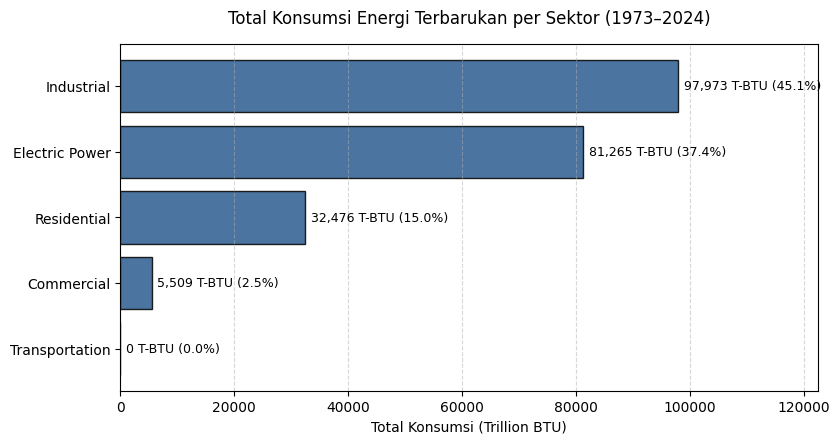

In [18]:
sector_totals = (
    raw_df.assign(Sector=raw_df['Sector'].replace({'Commerical': 'Commercial'}))
    .groupby('Sector')['Total Renewable Energy']
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(9, 4.5))
bars = plt.barh(sector_totals.index, sector_totals.values, color='#2b5c8f', edgecolor='black', alpha=0.85)

total_all = sector_totals.sum()
for bar in bars:
    width = bar.get_width()
    pct = (width / total_all) * 100
    plt.text(width + 1000, bar.get_y() + bar.get_height()/2, 
             f'{width:,.0f} T-BTU ({pct:.1f}%)', 
             va='center', fontsize=9)

plt.title('Total Konsumsi Energi Terbarukan per Sektor (1973–2024)', pad=15)
plt.xlabel('Total Konsumsi (Trillion BTU)', fontsize=10)
plt.xlim(0, sector_totals.max() * 1.25)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

> **Temuan Plot 1 (Ketimpangan Skala Sektor):** Terjadi ketimpangan konsumsi yang sangat ekstrem antar-sektor: sektor `Industrial` dan `Electric Power` mendominasi `>82%` dari total konsumsi historis, sementara `Commercial` hanya menyumbang `<3%`. Temuan ini memberi sinyal kuat bahwa model regresi **wajib** memiliki parameter *intercept* dan kemiringan tren yang terpisah untuk setiap sektor.

### 4.2 Visualisasi EDA 2: Heatmap Pola Nilai 0 (*Zero-Inflation Matrix*)
**Tujuan:** Memetakan persentase nilai `0` di seluruh kombinasi Sektor dan Jenis Energi untuk melihat spesialisasi energi tiap sektor serta memvalidasi anomali data secara visual.

In [19]:
zero_matrix = (raw_df[num_cols] == 0).groupby(
    raw_df["Sector"].replace({"Commerical": "Commercial"})
).mean() * 100

# zero_matrix.head()


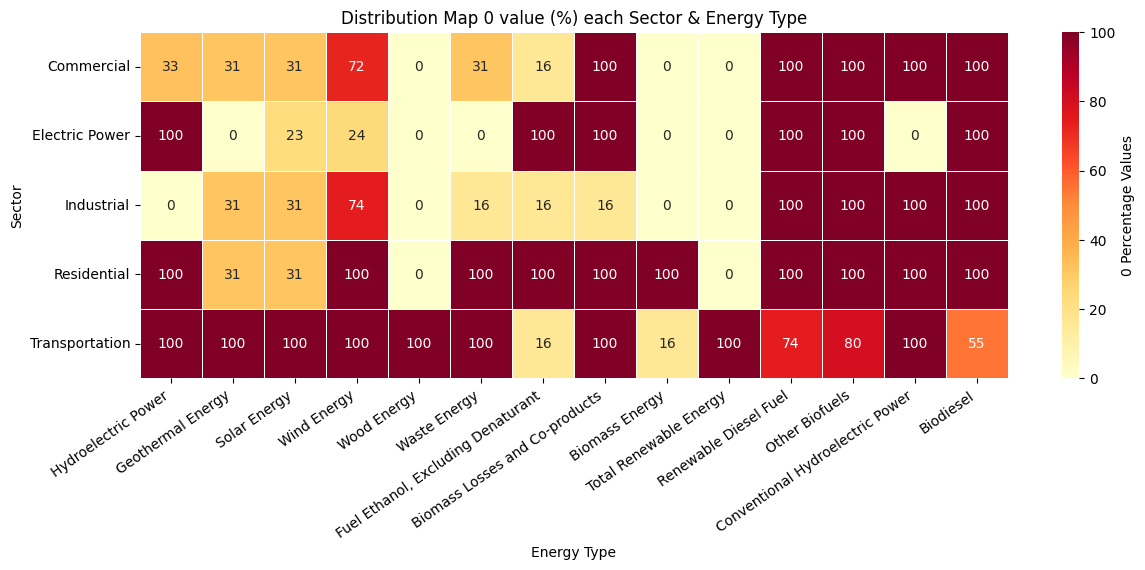

In [20]:
plt.figure(figsize=(14,4.5))

sns.heatmap(zero_matrix,annot=True, fmt='.0f',cmap='YlOrRd',linewidths=0.5,cbar_kws={'label' : '0 Percentage Values'})
plt.title('Distribution Map 0 value (%) each Sector & Energy Type')
plt.xlabel('Energy Type')
plt.ylabel('Sector')
plt.xticks(rotation=35, ha='right')
plt.show()

> **Takeaway Plot 2 (Zero-Inflation Matrix):**
> - Sektor `Transportation` memiliki **`100%` nilai `0`** pada target `Total Renewable Energy`, meskipun biofuel seperti `Fuel Ethanol, Excluding Denaturant` (`16%` nol), `Biodiesel` (`55%` nol), `Renewable Diesel Fuel` (`74%` nol), dan `Other Biofuels` (`80%` nol) tercatat aktif. Ini membuktikan bahwa dataset tidak mengagregasi biofuel transportasi ke kolom target sehingga `Transportation` harus didrop.
> - Dua kolom hidro saling melengkapi tanpa tumpang tindih (*mutually exclusive*): `Electric Power` bernilai **`100%` nol** di `Hydroelectric Power` dan **`0%` nol** di `Conventional Hydroelectric Power`, sedangkan `Industrial` (`0%` vs `100%`) dan `Commercial` (`33%` vs `100%`) bernilai sebaliknya — memvalidasi rencana penggabungan menjadi satu fitur `hydro`.
> - `Wood Energy` terisi konsisten (`0%` nol) di empat sektor utama, sedangkan biofuel cair modern (`Renewable Diesel Fuel`, `Other Biofuels`, `Biodiesel`) bernilai **`100%` nol** di keempat sektor tersebut, menjelaskan dominasi angka nol global (`>90%`) pada audit tabel sebelumnya.

### 4.3 Visualisasi EDA 3: Tren Deret Waktu & Sebaran Bulanan per Sektor (1973–2023)
**Tujuan:** Mengamati arah tren jangka panjang (data bulanan + *12-Month Moving Average*) serta distribusi bulanan tiap sektor (`Bulan 1–12`).

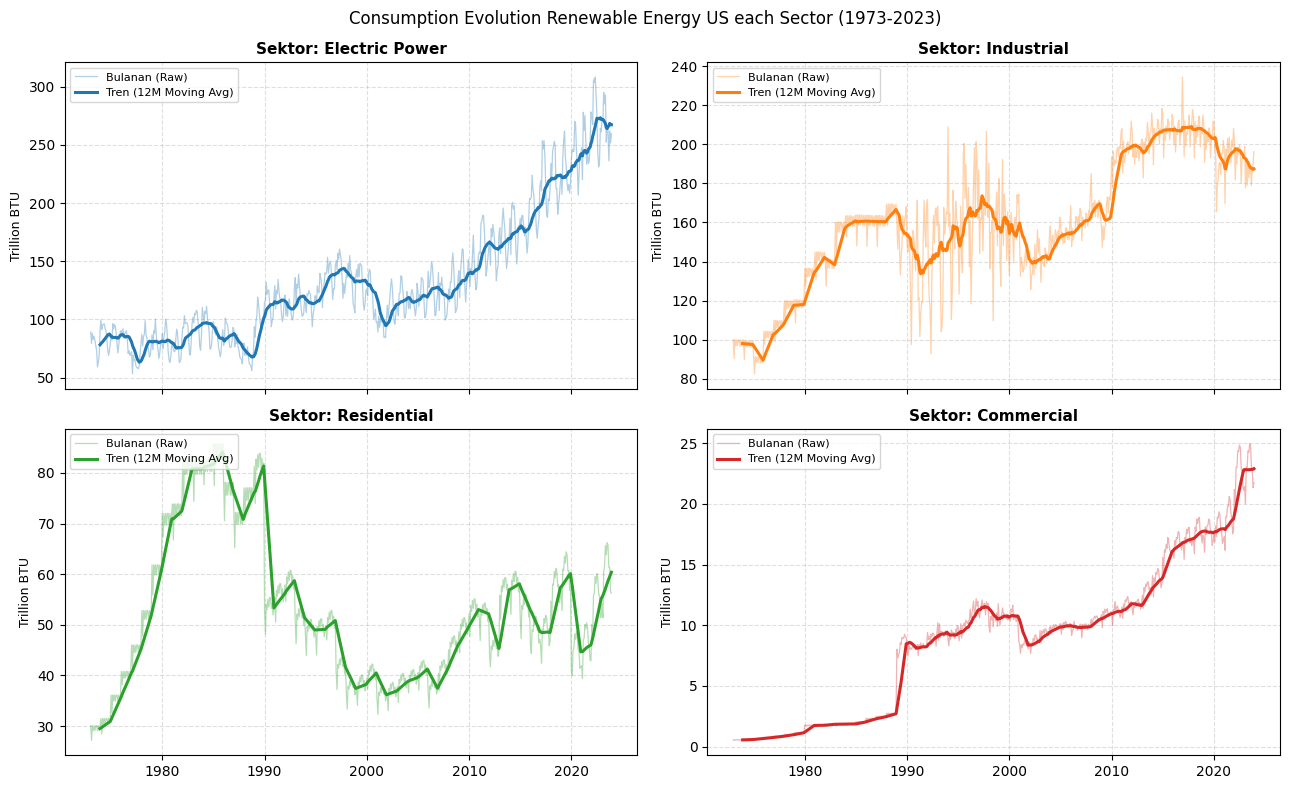

In [21]:
ts_df = raw_df.assign(
    Sector=raw_df["Sector"].replace({"Commerical": "Commercial"}),
    date=pd.to_datetime({"year": raw_df["Year"], "month": raw_df["Month"], "day": 1}),
).query("Sector != 'Transportation' and Year <= 2023").sort_values(['Sector','date'])

sectors = ['Electric Power', 'Industrial', 'Residential', 'Commercial']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, axes = plt.subplots(2,2, figsize=(13,8), sharex=True)
for ax, sector, color in zip(axes.ravel(), sectors, colors):
    sub = ts_df[ts_df['Sector'] == sector].set_index('date')['Total Renewable Energy']
    ma_12 = sub.rolling(window=12).mean()  # 12-Months Trend
    
    ax.plot(sub.index, sub.values, color=color, alpha=0.35, linewidth=0.9, label='Bulanan (Raw)')
    ax.plot(ma_12.index, ma_12.values, color=color, linewidth=2.2, label='Tren (12M Moving Avg)')
    
    ax.set_title(f'Sektor: {sector}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Trillion BTU', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper left', fontsize=8)

fig.suptitle('Consumption Evolution Renewable Energy US each Sector (1973-2023)')
plt.tight_layout()
plt.show()

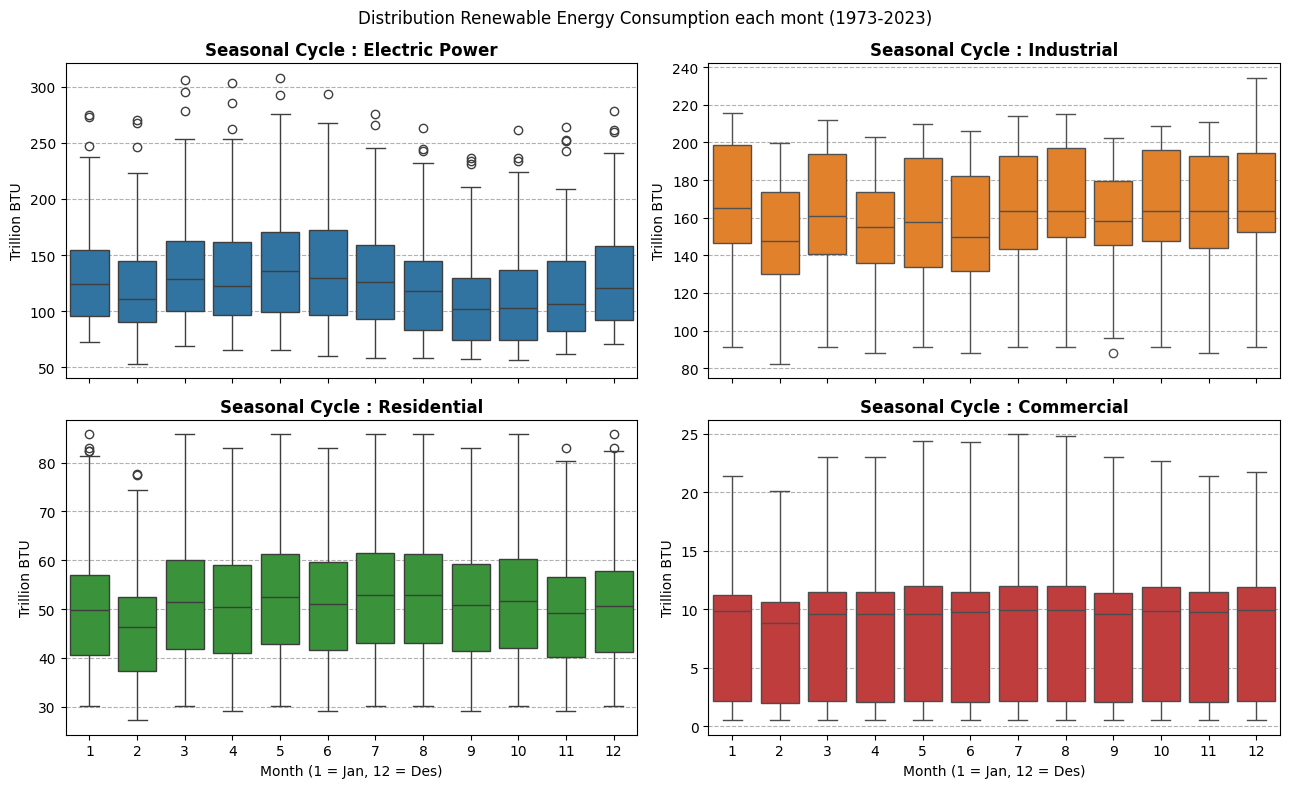

In [22]:
fig, axes = plt.subplots(2,2, figsize=(13,8), sharex=True)

for ax, sector, color in zip(axes.ravel(), sectors, colors):
    sub = ts_df[ts_df['Sector'] == sector]

    sns.boxplot(
        data=sub,
        x='Month',
        y='Total Renewable Energy',
        ax=ax,
        color=color
    )

    ax.set_title(f'Seasonal Cycle : {sector}',fontweight='bold')
    ax.set_ylabel('Trillion BTU')
    ax.set_xlabel('Month (1 = Jan, 12 = Des)')
    ax.grid(axis='y', linestyle='--')
fig.suptitle('Distribution Renewable Energy Consumption each mont (1973-2023)')
plt.tight_layout()
plt.show()

> **Takeaway Plot 3 (Tren 51 Tahun & Distribusi Bulanan Mentah):**
> - **Divergensi Tren Non-Linear Antar-Sektor:** Keempat sektor menunjukkan arah dan laju tren yang sangat berbeda. `Electric Power` tumbuh akseleratif dari bawah `100` hingga menembus `>300 Trillion BTU`; `Commercial` mengalami lonjakan struktural sekitar `1989–1990` dan terus mendaki ke `~25 Trillion BTU`; `Industrial` meningkat hingga awal `1990`-an, berfluktuasi di rentang `~140–210 Trillion BTU`, lalu melandai pasca-`2020`; sementara `Residential` membentuk gelombang non-monoton (puncak `~85` di era 1980-an, turun di bawah `40` sekitar 2000-an, lalu naik kembali menuju `~60`). Pola ini membuktikan model wajib memiliki *intercept* dan kemiringan tren terpisah per sektor (`Sector × t`).
> - **Siklus Bulanan pada *Boxplot*:** Pada `Electric Power`, distribusi median meningkat pada bulan **Mei–Juni** (disertai *outlier* atas `>300 Trillion BTU` dari tahun-tahun mutakhir) dan merendah pada **September–Oktober**. Di sektor `Industrial`, `Residential`, dan `Commercial`, bulan **Februari** konsisten sedikit lebih rendah akibat jumlah hari kalender yang lebih pendek (`28/29` hari). Karena nilai mentah 51 tahun mencampur efek tren kenaikan level dengan siklus musiman, pada **Plot 4** konsumsi tiap bulan dinormalkan terhadap rata-rata tahunannya.

### 4.4 Visualisasi EDA 4: Indeks Rasio Musiman Antar-Sektor (1973–2023)
**Objective:** Menghitung rasio konsumsi bulanan terhadap rata-rata tahunan tiap sektor guna mengisolasi sinyal musiman murni dari tren kenaikan level jangka panjang.

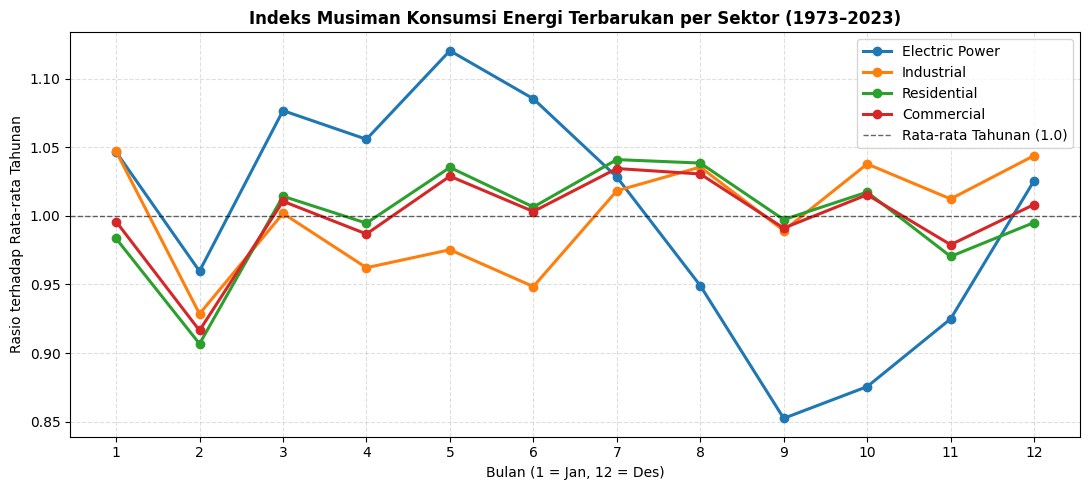

In [23]:
# Hitung rata-rata tahunan per sektor, lalu bagi setiap bulan dengan rata-rata tahunnya
ts_df['year_mean'] = ts_df.groupby(['Sector', 'Year'])['Total Renewable Energy'].transform('mean')
ts_df['seasonal_ratio'] = ts_df['Total Renewable Energy'] / ts_df['year_mean']

# Rata-ratakan rasio tersebut untuk tiap bulan (1 s/d 12)
seasonal_pattern = ts_df.groupby(['Sector', 'Month'])['seasonal_ratio'].mean().unstack(level=0)

plt.figure(figsize=(11, 5))
for sector, color in zip(sectors, colors):
    plt.plot(seasonal_pattern.index, seasonal_pattern[sector], marker='o', linewidth=2.2, label=sector, color=color)

plt.axhline(1.0, color='black', linestyle='--', linewidth=1, alpha=0.6, label='Rata-rata Tahunan (1.0)')
plt.title('Indeks Musiman Konsumsi Energi Terbarukan per Sektor (1973–2023)', fontsize=12, fontweight='bold')
plt.xlabel('Bulan (1 = Jan, 12 = Des)', fontsize=10)
plt.ylabel('Rasio terhadap Rata-rata Tahunan', fontsize=10)
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


> **Takeaway Plot 4 (Seasonality):** Pola musiman terbukti nyata dan berbeda antar-sektor. `Electric Power` menunjukkan volatilitas musiman tertinggi akibat ketergantungan pada siklus hidrologi musim semi (Maret–Juni) dan efek jumlah hari kalender (penurunan Februari), sementara sektor `Industrial` relatif stabil sepanjang tahun. Ini memvalidasi pentingnya memasukkan fitur `Month` (musiman) ke dalam model regresi.

### 4.5 Uji Hipotesis Statistik Formal (ANOVA & Kruskal-Wallis)
**Tujuan:** Membuktikan secara statistik apakah konsumsi energi terbarukan berbeda signifikan antar-sektor pengguna maupun antar-bulan kalender ($\alpha = 0.05$).

In [24]:
from scipy.stats import f_oneway, kruskal

stat_df = raw_df.assign(Sector=raw_df["Sector"].replace({"Commerical": "Commercial"}))
stat_df = (
    stat_df[(stat_df["Sector"] != "Transportation") & (stat_df["Year"] <= 2023)]
    .sort_values(["Sector", "Year", "Month"])
    .copy()
)

sector_groups = [
    g["Total Renewable Energy"].values for _, g in stat_df.groupby("Sector")
]
anova_f, anova_p = f_oneway(*sector_groups)
kw_sec_h, kw_sec_p = kruskal(*sector_groups)

stat_df["ma_12"] = stat_df.groupby("Sector")["Total Renewable Energy"].transform(
    lambda s: s.rolling(12, center=True).mean()
)
ratio_df = stat_df.dropna(subset=["ma_12"]).copy()
ratio_df["seasonal_ratio"] = ratio_df["Total Renewable Energy"] / ratio_df["ma_12"]

month_groups = [g["seasonal_ratio"].values for _, g in ratio_df.groupby("Month")]
kw_mon_h, kw_mon_p = kruskal(*month_groups)

print(
    f"Inter-Sector Difference -> One-Way ANOVA F={anova_f:.2f} (p={anova_p:.4e}) | Kruskal H={kw_sec_h:.2f} (p={kw_sec_p:.4e})"
)
print(
    f"Monthly Seasonality (Ratio to 12-Mo MA) -> Kruskal-Wallis H={kw_mon_h:.2f} (p={kw_mon_p:.4e})"
)

Inter-Sector Difference -> One-Way ANOVA F=2686.24 (p=0.0000e+00) | Kruskal H=2077.12 (p=0.0000e+00)
Monthly Seasonality (Ratio to 12-Mo MA) -> Kruskal-Wallis H=701.83 (p=2.1901e-143)
